# SymPhase tutorial 14 — spin-space-group numbers for any order, and magnon–phonon coupling

**Part A.** Every magnetic order — collinear, coplanar or non-coplanar — gets the **oriented spin-space-group (OSSG) number** of
X. Chen *et al.*, Phys. Rev. X **14**, 031038 (2024). SymPhase calls their FindSpinGroup package (`pip install findspingroup`)
and cross-checks the magnetic space group it derives against its own spglib result.

**Part B.** Magnons and phonons as **one harmonic system**: spin deviations $(X_a, Y_a)$ and atomic displacements/momenta
$(u_{j\alpha}, P_{j\alpha})$ are canonical pairs; the bond-length dependence of the exchange,
$J_{ij}(\mathbf d_0+\delta\mathbf d)=J_{ij}+\sum_\gamma G^\gamma_{ij}\,\delta d_\gamma$, couples them. The Bloch Hessian is diagonalised
symplectically → hybrid "magnon-polaron" bands with a magnon weight per mode.

In [1]:
# run this first (works from the repository's notebooks/ folder)
import os, sys
sys.path.insert(0, os.path.abspath(".."))      # use the local package if not pip-installed
EX = os.path.abspath("../examples")
%matplotlib inline

In [2]:
import numpy as np, spglib, math, copy, warnings
import matplotlib.pyplot as plt
warnings.simplefilter("ignore")
from symphase import analyze_tensors
from symphase.tensors import read_poscar
from symphase.magphon import analyse_mp, bond_springs, read_magnetoelastic, plot_mp
from symphase.qha import QHA, plot_qha, EV_A3_TO_GPA
from symphase.thermo import FiniteTHull, KB
from symphase.hull import load_csv
a = 3.0
lat, fr = np.diag([a, 12, 12]), np.zeros((1, 3))
ds = spglib.get_symmetry_dataset((lat, fr, [0])); m0 = np.array([[0, 0, 2.0]])
mpdir = f"{EX}/vasp/MagnonPhonon_FM_chain"
def fm_chain(lam=6.0, dJdr=None, J=-5.0, K=0.3, n_per=120):
    me = None
    if lam:
        G = np.zeros((3, 3)); G[0, 2] = G[2, 0] = lam
        me = {(0, 0, (1, 0, 0)): [(0, G)]}
    return analyse_mp(lat, fr, [0], ["Fe"], m0, ds.rotations, ds.translations, springs=[(0, 0, [1, 0, 0], 600.0, 300.0)],
                      magnetoelastic=me, dJdr=dJdr, J=[J], K=K, K_axis=[0, 0, 1], spin=1.0, rmax=3.1, n_per=n_per)
tri = f"{EX}/vasp/Triangular_120AFM_INCAR"
def triangular(dJdr=1.5):
    t = analyze_tensors(tri, tensors="charge", ossg="no")
    p = read_poscar(f"{tri}/POSCAR"); syms = t["structure"]["symbols"]; ty = [0] * len(syms)
    d3 = spglib.get_symmetry_dataset((p["lattice"], p["frac"], ty))
    return analyse_mp(p["lattice"], p["frac"], ty, syms, np.array(t["structure"]["moments"]), d3.rotations, d3.translations,
                      springs=bond_springs(p["lattice"], p["frac"], ty, 3.6, 400.0, 150.0), dJdr=[dJdr], J=[1.0],
                      spin=1.5, rmax=3.6, n_per=40)
ni = QHA.debye_gruneisen(0.0, 10.90, 186.0, 4.6, 450.0, 1.95)          # toy fcc Ni (Debye–Grüneisen)
qcsv = f"{EX}/hull/NiAl_qha.csv"


## A. OSSG numbers (Chen et al. 2024) for collinear and non-collinear orders

In [3]:
rows = []
for d in ["RuO2_Neel001_noSOC", "MnTe_altermagnet_INCAR", "Mn3Sn_allin", "Triangular_120AFM_INCAR", "CantedChain_DMI_INCAR"]:
    r = analyze_tensors(f"{EX}/vasp/{d}", tensors="charge")
    o = r["spin_group"]["ossg"]
    rows.append((d, o["index"], o["conf"], o["spin_space_point_group_hm"], o["msg_bns_number"], r["magnetic"]["bns_number"]))
print(f"{'example':<26s} {'OSSG index':<16s} {'order':<10s} {'spin PG':<8s} MSG(FSG)  MSG(SymPhase)")
for row in rows:
    print(f"{row[0]:<26s} {row[1]:<16s} {row[2]:<10s} {row[3]:<8s} {row[4]:<9s} {row[5]}")

example                    OSSG index       order      spin PG  MSG(FSG)  MSG(SymPhase)
RuO2_Neel001_noSOC         136.65.1.1.L     Collinear  ∞/mm     136.499   136.499
MnTe_altermagnet_INCAR     194.164.1.1.L    Collinear  ∞/mm     194.268   194.268
Mn3Sn_allin                194.6.1.1.P      Coplanar   6/mmm    194.271   194.271
Triangular_120AFM_INCAR    191.187.3.1.P    Coplanar   -62m     189.223   189.223
CantedChain_DMI_INCAR      123.123.2.2.P2   Coplanar   mm2      51.295    51.295


* The index starts with $G_0.L_0$: $G_0$ is the space group of the spatial parts and $L_0$ the spin-preserving subgroup — it coincides with
  SymPhase's own subgroup $H$ (RuO₂: Cmmm 65, MnTe: P-3m1 164). Then follow the enumeration indices and a suffix for the spin-only
  group (**L** collinear, **P** coplanar, none for non-coplanar). Full definitions: Chen *et al.*, PRX **14**, 031038 (2024).
* Collinear SSGs are also labelled by SymPhase's own scheme (BNS number of the $C_{2\perp}\to T$ black-and-white group, 1421 groups) —
  both are printed by `symphase tensors`.
* The magnetic space group that FindSpinGroup derives for the SOC case agrees with SymPhase's spglib result in every case: an independent check.

The same works for the non-coplanar **skyrmion crystal** of tutorial 12 (written by the supercell workflow):

In [4]:
from symphase.supercell import run_supercell, write_outputs
from symphase.magnons import read_exchange_file
import tempfile
sk = f"{EX}/vasp/Skyrmion_triangular"; ps = read_poscar(f"{sk}/POSCAR")
dss = spglib.get_symmetry_dataset((ps["lattice"], ps["frac"], [0]))
rsk = run_supercell(ps["lattice"], ps["frac"], [0], ["Mn"], np.array([[0, 0, 2.0]]), dss.rotations, dss.translations,
                    size=[10, 10, 1], restarts=2, spectrum=False, exchange=read_exchange_file(f"{sk}/J_DMI.dat"), spin=1.0,
                    rmax=3.1, field=[0, 0, 14])
out = write_outputs(rsk, ["Mn"], np.array([[0, 0, 2.0]]), tempfile.mkdtemp())
o = analyze_tensors(out, tensors="charge")["spin_group"]["ossg"]
print("skyrmion crystal:", rsk["character"]["cls"], "->  OSSG", o["index"], o["conf"], " MSG", o["msg_symbol"], o["msg_bns_number"])

skyrmion crystal: skyrmion crystal (3Q, 3 skyrmions per supercell) ->  OSSG 191.6.1.2 Noncoplanar  MSG P6m'm' 183.189


## B. Magnon–phonon coupling

### B1. Ferromagnetic chain with a magnetoelastic (pseudo-dipolar) term

$J=-5$ meV, easy axis $K=0.3$ meV, $S=1$, Fe masses, springs $k_L=600$, $k_T=300$ meV/Å². The derivative of the bond tensor along the chain
has a symmetric $xz$ element $\lambda=6$ meV/Å (`examples/vasp/MagnonPhonon_FM_chain/magnetoelastic.dat`): a longitudinal displacement tilts
the easy axis → linear coupling to the **longitudinal** acoustic phonon. Colour = magnon weight; dashed = uncoupled.

anticrossing at k = 0.026 1/Å, ω ≈ 0.352 meV, gap = 0.3899 meV
anticrossing at k = 0.445 1/Å, ω ≈ 7.707 meV, gap = 1.1112 meV


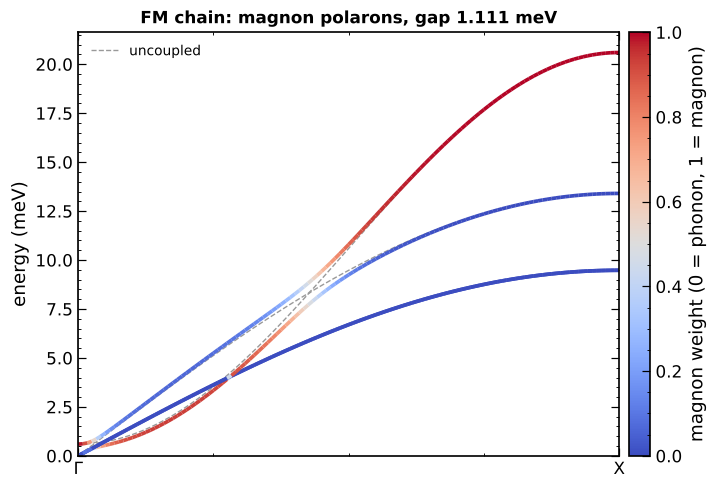

In [5]:
r = fm_chain()
plot_mp(r, title=f"FM chain: magnon polarons, gap {r['max_gap']:.3f} meV");
for g in r["gaps"]:
    print(f"anticrossing at k = {g['x']:.3f} 1/Å, ω ≈ {g['omega']:.3f} meV, gap = {g['gap']:.4f} meV")

**Analytic check.** One magnon ($\omega_m$) coupled to one phonon ($\omega_p$, $\kappa=\hbar^2/M$) through $H_c = g\,X u$ obeys
$(\omega^2-\omega_m^2)(\omega^2-\omega_p^2)=\omega_m\kappa g^2$ with $g = 2\lambda S^{3/2}|\sin ka|$ here:

In [6]:
from symphase.magphon import HB2_AMU
k = r["q"][:, 0]; S, J, K, lam = 1.0, -5.0, 0.3, 6.0
wm = 2 * S * abs(J) * (1 - np.cos(k * a)) + 2 * K * S
kap = HB2_AMU / 55.845; wL = np.sqrt(kap * 1200 * (1 - np.cos(k * a))); wT = np.sqrt(kap * 600 * (1 - np.cos(k * a)))
g = 2 * lam * S ** 1.5 * np.abs(np.sin(k * a)); B = wm**2 + wL**2; C = wm**2 * wL**2 - wm * kap * g**2
ref = np.sort(np.c_[np.sqrt((B + np.sqrt(B*B - 4*C)) / 2), np.sqrt(np.maximum((B - np.sqrt(B*B - 4*C)) / 2, 0)), wT, wT], axis=1)
print("max |SymPhase − analytic| =", np.abs(r["omega"][1:] - ref[1:]).max(), "meV")

max |SymPhase − analytic| = 2.7255975254547593e-14 meV


The gap grows **linearly** with the magnetoelastic constant (first-order level repulsion):

{2: np.float64(0.3709), 4: np.float64(0.7396), 6: np.float64(1.1099), 8: np.float64(1.482)}


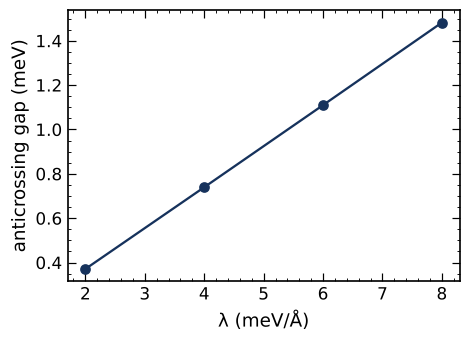

In [7]:
lams = [2, 4, 6, 8]
gaps = [fm_chain(lam=l, n_per=200)["max_gap"] for l in lams]
fig, ax = plt.subplots(figsize=(4.6, 3.2)); ax.plot(lams, gaps, "o-", color="#16325c")
ax.set_xlabel("λ (meV/Å)"); ax.set_ylabel("anticrossing gap (meV)")
print(dict(zip(lams, np.round(gaps, 4))))

### B2. Exchange striction needs non-collinear spins

Isotropic striction $G^\gamma = (\mathrm dJ/\mathrm dr)\,\hat r_\gamma\,\mathbb 1$ enters as $x_a\cdot v_b$ — zero for collinear order. The FM chain is
unchanged, the 120° triangular antiferromagnet couples:

collinear FM chain, dJ/dr = 3 meV/Å:  max |ω − ω0| = 0.0 meV


120° triangular, dJ/dr = 1.5 meV/Å :  max |ω − ω0| = 0.0332 meV; 3 magnon + 9 phonon branches


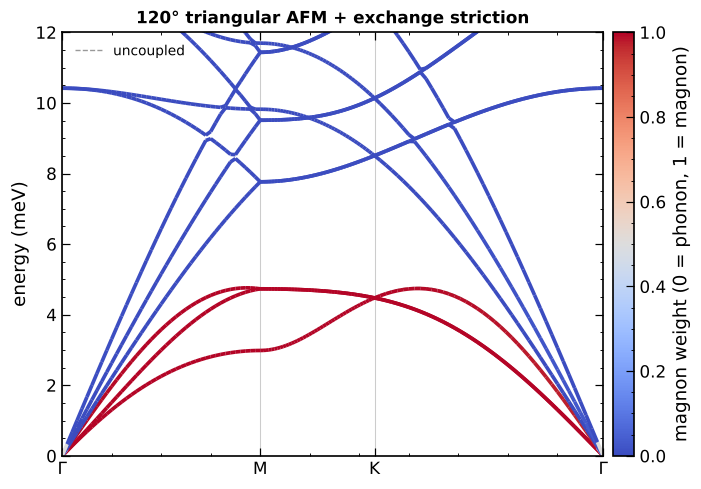

In [8]:
r0 = fm_chain(lam=0, dJdr=[3.0])
print("collinear FM chain, dJ/dr = 3 meV/Å:  max |ω − ω0| =", np.nanmax(np.abs(r0["omega"] - r0["omega0"])), "meV")
rt = triangular(dJdr=1.5)
print("120° triangular, dJ/dr = 1.5 meV/Å :  max |ω − ω0| =", round(float(np.nanmax(np.abs(rt["omega"] - rt["omega0"]))), 4),
      "meV;", rt["n_magnon"], "magnon +", rt["n_phonon"], "phonon branches")
plot_mp(rt, title="120° triangular AFM + exchange striction", ylim=(0, 12));

### B3. Phonons from phonopy

`symphase magnons ... --phonons phonopy_params.yaml` uses DFT force constants (same primitive cell and atom order as the POSCAR).
SymPhase converts phonopy's dynamical matrix to $\Phi(\mathbf k)$ in its own phase convention — identical to the spring model when the
force constants are those springs (checked to $10^{-12}$ in `tests/`).

### B4. Command line
```bash
cd examples/vasp/MagnonPhonon_FM_chain
symphase magnons --J -5 --K 0.3 --K-axis 0 0 1 --spin 1 --rmax 3.1 --phonons springs.dat --magnetoelastic magnetoelastic.dat
symphase magnons --J 1.0 --rmax 3.6 --springs-nn 400 150 3.6 --dJdr 1.5           # 120° triangular (Triangular_120AFM_INCAR)
symphase magnons ... --phonons phonopy_params.yaml --magnetoelastic dJ.dat          # DFT phonons
```